In [ ]:
import os

import pandas as pd
import matplotlib.pyplot as plt

from sqlalchemy import create_engine
from dotenv import load_dotenv
from pathlib import Path


PROJECT_ROOT = Path.cwd().parent
load_dotenv(PROJECT_ROOT / ".env")


db_user = os.getenv("DB_USER")
db_password = os.getenv("DB_PASSWORD")
db_host = os.getenv("DB_HOST", "localhost")
db_port = os.getenv("DB_PORT", "5432")
db_name = os.getenv("DB_NAME")


if db_password:
    db_url = (
        f"postgresql+psycopg2://"
        f"{db_user}:{db_password}"
        f"@{db_host}:{db_port}/{db_name}"
    )
else:
    db_url = (
        f"postgresql+psycopg2://"
        f"{db_user}@{db_host}:{db_port}/{db_name}"
    )


engine = create_engine(db_url)

In [10]:
query = """
SELECT *
FROM dbt.mart_product_daily
ORDER BY date
"""

df = pd.read_sql(query, engine)
df["date"] = pd.to_datetime(df["date"])

print(df.shape)
print(df["date"].min(), df["date"].max())

(1091, 25)
2023-10-16 00:00:00 2026-10-10 00:00:00


In [11]:
review_df = df[df["review_count"] > 0].copy()

review_df[
    [
        "date",
        "wholesale_price_weighted",
        "wholesale_price_weighted_strict",
        "review_qty_share_pct"
    ]
]

,date,wholesale_price_weighted,wholesale_price_weighted_strict,review_qty_share_pct
805,2025-12-29,11263.407779,968.951542,90.691042
897,2026-03-31,2061.744837,1123.679148,4.286143
913,2026-04-16,1433.482057,1215.403266,1.115847
945,2026-05-18,728.563873,701.344692,0.213384


In [12]:
review_df["price_sensitivity_pct"] = (
    (
        review_df["wholesale_price_weighted"]
        - review_df["wholesale_price_weighted_strict"]
    ).abs()
    /
    review_df["wholesale_price_weighted_strict"]
    * 100
)

review_df[
    [
        "date",
        "wholesale_price_weighted",
        "wholesale_price_weighted_strict",
        "review_qty_share_pct",
        "price_sensitivity_pct"
    ]
]

,date,wholesale_price_weighted,wholesale_price_weighted_strict,review_qty_share_pct,price_sensitivity_pct
805,2025-12-29,11263.407779,968.951542,90.691042,1062.432515
897,2026-03-31,2061.744837,1123.679148,4.286143,83.481632
913,2026-04-16,1433.482057,1215.403266,1.115847,17.942916
945,2026-05-18,728.563873,701.344692,0.213384,3.880999


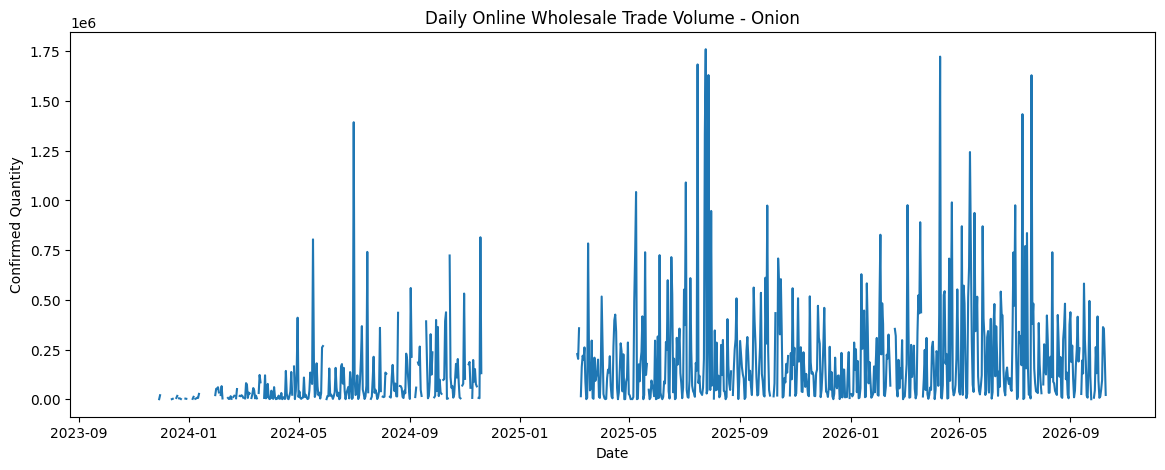

In [13]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["date"],
    df["wholesale_qty_clean"]
)

plt.title("Daily Online Wholesale Trade Volume - Onion")
plt.xlabel("Date")
plt.ylabel("Confirmed Quantity")

plt.show()

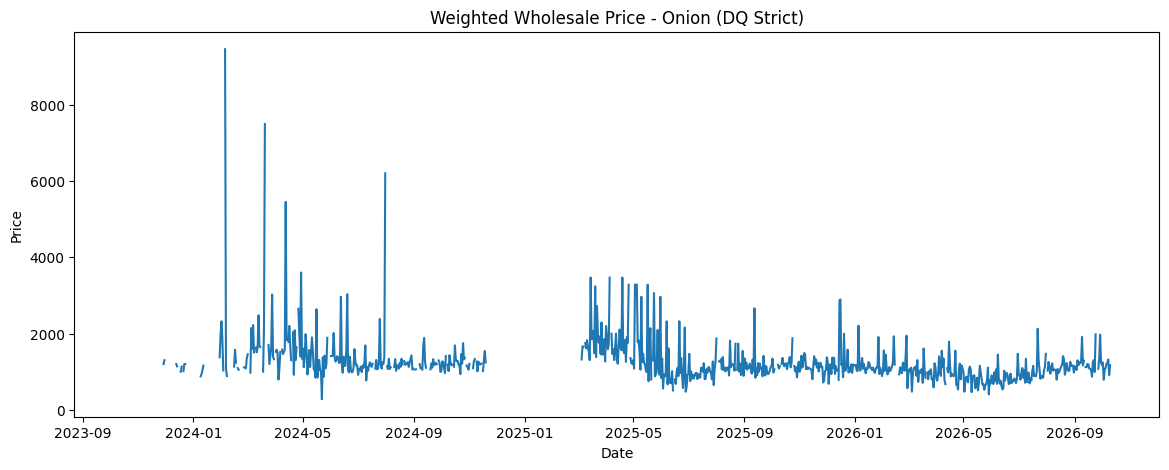

In [14]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["date"],
    df["wholesale_price_weighted_strict"]
)

plt.title("Weighted Wholesale Price - Onion (DQ Strict)")
plt.xlabel("Date")
plt.ylabel("Price")

plt.show()

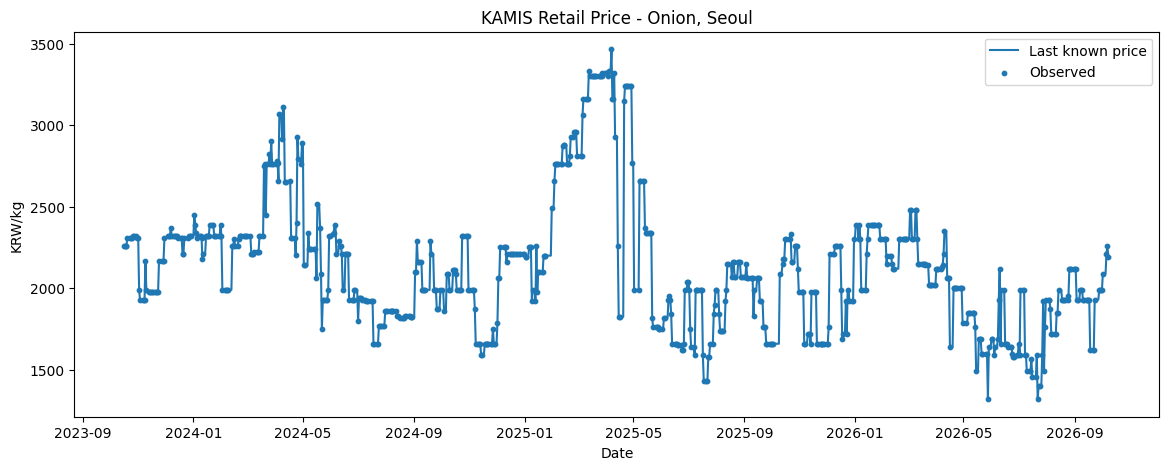

In [15]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["date"],
    df["retail_price_latest"],
    label="Last known price"
)

observed = df[df["is_retail_price_observed"]]

plt.scatter(
    observed["date"],
    observed["retail_price_observed"],
    s=10,
    label="Observed"
)

plt.title("KAMIS Retail Price - Onion, Seoul")
plt.xlabel("Date")
plt.ylabel("KRW/kg")
plt.legend()

plt.show()

In [16]:
df["wholesale_qty_ma30"] = (
    df["wholesale_qty_clean"]
    .rolling(30, min_periods=10)
    .mean()
)

df["wholesale_price_ma30"] = (
    df["wholesale_price_weighted_strict"]
    .rolling(30, min_periods=10)
    .mean()
)

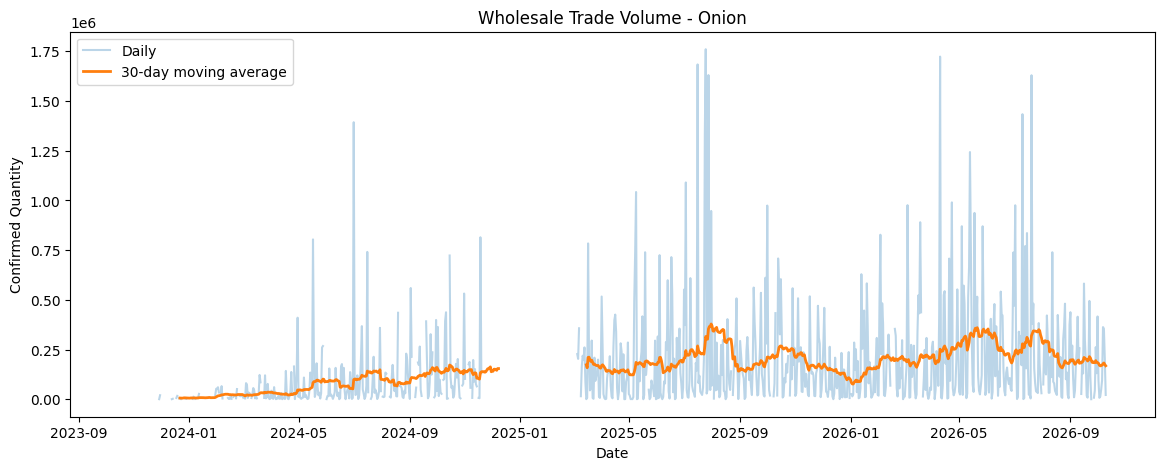

In [17]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["date"],
    df["wholesale_qty_clean"],
    alpha=0.3,
    label="Daily"
)

plt.plot(
    df["date"],
    df["wholesale_qty_ma30"],
    linewidth=2,
    label="30-day moving average"
)

plt.title("Wholesale Trade Volume - Onion")
plt.xlabel("Date")
plt.ylabel("Confirmed Quantity")
plt.legend()

plt.show()

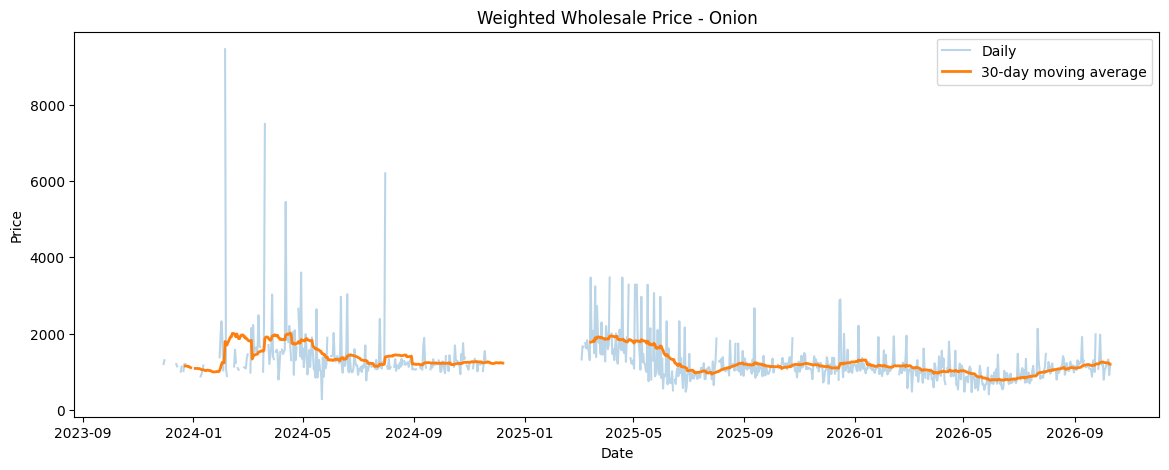

In [18]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["date"],
    df["wholesale_price_weighted_strict"],
    alpha=0.3,
    label="Daily"
)

plt.plot(
    df["date"],
    df["wholesale_price_ma30"],
    linewidth=2,
    label="30-day moving average"
)

plt.title("Weighted Wholesale Price - Onion")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()

plt.show()

In [19]:
price_check = (
    df[
        [
            "date",
            "wholesale_qty_clean",
            "wholesale_qty_reference",
            "wholesale_price_weighted_strict",
            "wholesale_variant_count",
            "review_count",
            "hard_anomaly_count"
        ]
    ]
    .sort_values(
        "wholesale_price_weighted_strict",
        ascending=False
    )
    .head(20)
)

price_check

,date,wholesale_qty_clean,wholesale_qty_reference,wholesale_price_weighted_strict,wholesale_variant_count,review_count,hard_anomaly_count
112,2024-02-05,20989.0,16199.0,9463.000000,2.0,0.0,0.0
156,2024-03-20,85147.6,80297.6,7500.778544,3.0,0.0,0.0
289,2024-07-31,40598.0,33308.0,6207.310916,5.0,0.0,0.0
179,2024-04-12,31240.0,28240.0,5456.794051,3.0,0.0,0.0
196,2024-04-29,144287.8,140427.8,3602.010882,3.0,0.0,0.0
537,2025-04-05,378.4,378.4,3469.000000,1.0,0.0,0.0
551,2025-04-19,138.4,18.4,3469.000000,2.0,0.0,0.0
516,2025-03-15,314.0,260.0,3469.000000,2.0,0.0,0.0
567,2025-05-05,376.8,376.8,3281.000000,1.0,0.0,0.0
558,2025-04-26,76.8,76.8,3281.000000,1.0,0.0,0.0


In [20]:
df["wholesale_price_weighted_strict"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 1.00]
)

0.500    1128.083924
0.750    1328.952809
0.900    1745.040750
0.950    2098.275160
0.990    3281.000000
0.995    3580.064087
1.000    9463.000000
Name: wholesale_price_weighted_strict, dtype: float64

In [21]:
weekly = (
    df.set_index("date")
      .resample("W-SUN")
      .agg(
          wholesale_qty=("wholesale_qty_clean", "sum"),
          wholesale_qty_obs=("wholesale_qty_clean", "count"),

          wholesale_price=(
              "wholesale_price_weighted_strict",
              "median"
          ),
          wholesale_price_obs=(
              "wholesale_price_weighted_strict",
              "count"
          ),

          retail_price=(
              "retail_price_observed",
              "median"
          ),
          retail_price_obs=(
              "retail_price_observed",
              "count"
          )
      )
      .reset_index()
)

weekly.head()

,date,wholesale_qty,wholesale_qty_obs,wholesale_price,wholesale_price_obs,retail_price,retail_price_obs
0,2023-10-22,5300.0,3,1517.000000,2,2260.0,5
1,2023-10-29,1800.0,1,1300.000000,1,2310.0,5
2,2023-11-05,4200.0,1,1200.000000,1,2310.0,5
3,2023-11-12,5250.0,2,1244.500000,2,1930.0,5
4,2023-11-19,6510.0,2,1255.072046,2,1980.0,5


In [22]:
weekly_valid = weekly[
    (weekly["wholesale_price_obs"] >= 3) &
    (weekly["retail_price_obs"] >= 3)
].copy()

In [23]:
weekly_valid["wholesale_price_pct"] = (
    weekly_valid["wholesale_price"]
    .pct_change() * 100
)

weekly_valid["retail_price_pct"] = (
    weekly_valid["retail_price"]
    .pct_change() * 100
)

weekly_valid["wholesale_qty_pct"] = (
    weekly_valid["wholesale_qty"]
    .pct_change() * 100
)

In [24]:
monthly = (
    df.assign(month=df["date"].dt.month)
      .groupby("month")
      .agg(
          wholesale_qty_median=(
              "wholesale_qty_clean",
              "median"
          ),
          wholesale_price_median=(
              "wholesale_price_weighted_strict",
              "median"
          ),
          retail_price_median=(
              "retail_price_observed",
              "median"
          )
      )
      .reset_index()
)

monthly

,month,wholesale_qty_median,wholesale_price_median,retail_price_median
0,1,24939.00,1078.000000,2310.0
1,2,52908.80,1117.842980,2310.0
2,3,55891.15,1429.403332,2480.0
3,4,60794.00,1467.129498,2650.0
4,5,57310.20,1062.248241,1930.0
5,6,77461.40,978.064734,1820.0
6,7,81245.00,1028.114363,1770.0
7,8,84110.00,1125.119520,1860.0
8,9,159826.10,1145.138951,1990.0
9,10,96557.50,1189.220657,2190.0


In [25]:
lags = range(0, 5)

results = []

for lag in lags:
    temp = weekly_valid[
        [
            "wholesale_price_pct",
            "retail_price_pct"
        ]
    ].copy()

    # 도매가격 변화가 lag주 뒤 소매가격 변화와
    # 어떤 관계인지 확인
    temp["future_retail_pct"] = (
        temp["retail_price_pct"]
        .shift(-lag)
    )

    corr = (
        temp[
            [
                "wholesale_price_pct",
                "future_retail_pct"
            ]
        ]
        .dropna()
        .corr()
        .iloc[0, 1]
    )

    results.append({
        "lag_weeks": lag,
        "correlation": corr
    })

lag_result = pd.DataFrame(results)

lag_result

,lag_weeks,correlation
0,0,0.145896
1,1,0.023753
2,2,0.129452
3,3,-0.056057
4,4,-0.092814


In [26]:
price_volume_check = df[
    [
        "date",
        "wholesale_qty_reference",
        "wholesale_price_weighted_strict",
        "wholesale_variant_count"
    ]
].dropna()

price_volume_check["qty_bucket"] = pd.cut(
    price_volume_check["wholesale_qty_reference"],
    bins=[0, 100, 1000, 10000, 50000, 100000, float("inf")],
    labels=[
        "0-100",
        "100-1K",
        "1K-10K",
        "10K-50K",
        "50K-100K",
        "100K+"
    ]
)

price_volume_check.groupby(
    "qty_bucket",
    observed=True
).agg(
    days=("date", "count"),
    median_price=("wholesale_price_weighted_strict", "median"),
    mean_price=("wholesale_price_weighted_strict", "mean"),
    price_std=("wholesale_price_weighted_strict", "std")
)

,days,median_price,mean_price,price_std
qty_bucket,,,,
0-100,7,1980.000000,2151.857143,1233.619394
100-1K,33,1578.000000,1929.848485,764.361462
1K-10K,121,1162.000000,1206.107937,304.200465
10K-50K,209,1089.496060,1211.643914,801.762110
50K-100K,97,1181.076412,1341.006718,830.786541
100K+,367,1114.679526,1189.453862,382.870675


In [27]:
price_volume_check.groupby(
    "wholesale_variant_count"
).agg(
    days=("date", "count"),
    median_qty=("wholesale_qty_reference", "median"),
    median_price=("wholesale_price_weighted_strict", "median"),
    price_std=("wholesale_price_weighted_strict", "std")
)

,days,median_qty,median_price,price_std
wholesale_variant_count,,,,
1.0,95,3060.0,1222.000000,637.285343
2.0,125,10631.8,1141.418605,902.050619
3.0,153,41588.0,1119.444329,749.299963
4.0,226,128975.0,1084.506906,401.759292
5.0,147,180310.0,1181.076412,518.839933
6.0,60,238112.4,1196.555969,331.493398
7.0,22,362607.1,1082.474398,240.345102
8.0,6,499141.0,1024.801866,204.859228


In [28]:
weekly = (
    df.set_index("date")
      .resample("W-SUN")
      .agg(
          wholesale_qty=("wholesale_qty_clean", "sum"),
          wholesale_qty_obs=("wholesale_qty_clean", "count"),

          wholesale_price=(
              "wholesale_price_weighted_strict",
              "median"
          ),
          wholesale_price_obs=(
              "wholesale_price_weighted_strict",
              "count"
          ),

          retail_price=(
              "retail_price_observed",
              "median"
          ),
          retail_price_obs=(
              "retail_price_observed",
              "count"
          )
      )
      .reset_index()
)

# 전체 연속 주차 상태에서 먼저 변화율 계산
weekly["wholesale_price_pct"] = (
    weekly["wholesale_price"].pct_change() * 100
)

weekly["retail_price_pct"] = (
    weekly["retail_price"].pct_change() * 100
)

weekly["wholesale_qty_pct"] = (
    weekly["wholesale_qty"].pct_change() * 100
)

# 그 다음 분석 가능 여부 표시
weekly["is_valid"] = (
    (weekly["wholesale_price_obs"] >= 3) &
    (weekly["retail_price_obs"] >= 3)
)

/var/folders/9k/gfjrzlbs4m944f17wkmd4j600000gn/T/ipykernel_29880/2709212328.py:31: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  weekly["wholesale_price"].pct_change() * 100


In [29]:
results = []

for lag in range(0, 5):

    temp = weekly.copy()

    temp["future_retail_pct"] = (
        temp["retail_price_pct"].shift(-lag)
    )

    temp["future_valid"] = (
        temp["is_valid"].shift(-lag)
    )

    valid = temp[
        temp["is_valid"] &
        temp["future_valid"].fillna(False)
    ][
        [
            "wholesale_price_pct",
            "future_retail_pct"
        ]
    ].dropna()

    results.append({
        "lag_weeks": lag,
        "n": len(valid),
        "correlation": valid.corr().iloc[0, 1]
    })

lag_result = pd.DataFrame(results)
lag_result

/var/folders/9k/gfjrzlbs4m944f17wkmd4j600000gn/T/ipykernel_29880/2497861304.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp["future_valid"].fillna(False)
/var/folders/9k/gfjrzlbs4m944f17wkmd4j600000gn/T/ipykernel_29880/2497861304.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp["future_valid"].fillna(False)
/var/folders/9k/gfjrzlbs4m944f17wkmd4j600000gn/T/ipykernel_29880/2497861304.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_object

,lag_weeks,n,correlation
0,0,126,0.059227
1,1,118,0.034423
2,2,116,0.119874
3,3,117,-0.016888
4,4,113,-0.086944


In [30]:
import numpy as np

In [31]:
weekly["log_qty"] = np.log1p(
    weekly["wholesale_qty"]
)

weekly["log_wholesale_price"] = np.log(
    weekly["wholesale_price"]
)

weekly["qty_log_change"] = (
    weekly["log_qty"].diff()
)

weekly["wholesale_price_log_change"] = (
    weekly["log_wholesale_price"].diff()
)

In [32]:
results = []

for lag in range(0, 5):

    temp = weekly.copy()

    temp["future_price_change"] = (
        temp["wholesale_price_log_change"]
        .shift(-lag)
    )

    valid = temp[
        [
            "qty_log_change",
            "future_price_change"
        ]
    ].dropna()

    pearson = valid[
        "qty_log_change"
    ].corr(
        valid["future_price_change"]
    )

    # 순위 기반 상관
    # 극단값 및 비선형 관계에 덜 민감
    spearman = (
        valid["qty_log_change"].rank()
        .corr(
            valid["future_price_change"].rank()
        )
    )

    results.append({
        "lag_weeks": lag,
        "n": len(valid),
        "pearson": pearson,
        "spearman": spearman
    })

qty_price_lag = pd.DataFrame(results)

qty_price_lag

,lag_weeks,n,pearson,spearman
0,0,138,0.218776,0.147052
1,1,137,-0.075141,-0.096197
2,2,136,0.093311,0.020271
3,3,135,-0.028708,0.036872
4,4,134,-0.059777,-0.085540


In [33]:
weekly_reliable = (
    df[
        df["wholesale_qty_reference"] >= 1000
    ]
    .set_index("date")
    .resample("W-SUN")
    .agg(
        wholesale_qty=(
            "wholesale_qty_clean",
            "sum"
        ),
        wholesale_price=(
            "wholesale_price_weighted_strict",
            "median"
        ),
        price_obs=(
            "wholesale_price_weighted_strict",
            "count"
        )
    )
    .reset_index()
)

weekly_reliable["log_qty"] = np.log1p(
    weekly_reliable["wholesale_qty"]
)

weekly_reliable["log_price"] = np.log(
    weekly_reliable["wholesale_price"]
)

weekly_reliable["qty_change"] = (
    weekly_reliable["log_qty"].diff()
)

weekly_reliable["price_change"] = (
    weekly_reliable["log_price"].diff()
)

In [34]:
weekly = (
    df.set_index("date")
      .resample("W-SUN")
      .agg(
          wholesale_qty=(
              "wholesale_qty_clean",
              lambda x: x.sum(min_count=1)
          ),

          wholesale_qty_obs=(
              "wholesale_qty_clean",
              "count"
          ),

          wholesale_price=(
              "wholesale_price_weighted_strict",
              "median"
          ),

          wholesale_price_obs=(
              "wholesale_price_weighted_strict",
              "count"
          ),

          retail_price=(
              "retail_price_observed",
              "median"
          ),

          retail_price_obs=(
              "retail_price_observed",
              "count"
          )
      )
      .reset_index()
)

In [35]:
weekly["avg_daily_wholesale_qty"] = (
    weekly["wholesale_qty"]
    / weekly["wholesale_qty_obs"]
)

In [36]:
weekly["year"] = weekly["date"].dt.year
weekly["week"] = weekly["date"].dt.isocalendar().week.astype(int)

In [37]:
year_summary = (
    weekly.groupby("year")
    .agg(
        weeks=("date", "count"),

        median_weekly_qty=(
            "wholesale_qty",
            "median"
        ),

        median_daily_qty=(
            "avg_daily_wholesale_qty",
            "median"
        ),

        median_wholesale_price=(
            "wholesale_price",
            "median"
        ),

        median_retail_price=(
            "retail_price",
            "median"
        )
    )
)

year_summary

,weeks,median_weekly_qty,median_daily_qty,median_wholesale_price,median_retail_price
year,,,,,
2023,11,5250.0,3000.000000,1200.000000,2310.0
2024,52,404963.4,67493.900000,1209.943664,2210.0
2025,52,1102285.2,161917.914286,1162.680608,2080.0
2026,41,1371693.0,201124.714286,1012.317146,2000.0


In [38]:
weekly["qty_index"] = (
    weekly["avg_daily_wholesale_qty"]
    /
    weekly.groupby("year")[
        "avg_daily_wholesale_qty"
    ].transform("median")
)

In [39]:
weekly["month"] = weekly["date"].dt.month

seasonality = (
    weekly.groupby("month")
    .agg(
        qty_index_median=(
            "qty_index",
            "median"
        ),

        wholesale_price_median=(
            "wholesale_price",
            "median"
        ),

        retail_price_median=(
            "retail_price",
            "median"
        )
    )
    .reset_index()
)

seasonality

,month,qty_index_median,wholesale_price_median,retail_price_median
0,1,0.252519,1064.050797,2275.0
1,2,0.602011,1107.709697,2320.0
2,3,0.660871,1509.750000,2390.0
3,4,0.831917,1582.429932,2352.5
4,5,1.308908,1062.248241,2240.0
5,6,1.064376,944.386105,1875.0
6,7,1.919774,997.300973,1845.0
7,8,0.973269,1153.201209,1865.0
8,9,1.081320,1157.599172,1990.0
9,10,1.180310,1224.510609,2100.0


In [40]:
weekly["year"] = weekly["date"].dt.year
weekly["month"] = weekly["date"].dt.month

year_month = (
    weekly[
        weekly["year"].isin([2024, 2025, 2026])
    ]
    .groupby(["year", "month"])
    .agg(
        qty_index=(
            "qty_index",
            "median"
        ),
        wholesale_price=(
            "wholesale_price",
            "median"
        ),
        retail_price=(
            "retail_price",
            "median"
        )
    )
    .reset_index()
)

year_month

,year,month,qty_index,wholesale_price,retail_price
0,2024,1,0.125480,1012.500000,2320.0
1,2024,2,0.380696,1163.500000,2290.0
2,2024,3,0.477416,1616.500000,2320.0
3,2024,4,0.354865,1657.498953,2585.0
4,2024,5,1.039370,1286.487442,2240.0
5,2024,6,0.732455,1224.932392,2210.0
6,2024,7,2.078915,1173.164091,1922.5
7,2024,8,1.142839,1180.662452,1845.0
8,2024,9,2.030536,1183.945643,1990.0
9,2024,10,2.255712,1230.275878,2015.0


In [41]:
qty_pivot = year_month.pivot(
    index="month",
    columns="year",
    values="qty_index"
)

qty_pivot

year,2024,2025,2026
month,,,
1,0.125480,NaN,0.804676
2,0.380696,NaN,0.914629
3,0.477416,1.033130,0.634167
4,0.354865,0.831917,1.401258
5,1.039370,1.064141,1.533747
6,0.732455,1.154450,1.079457
7,2.078915,1.948281,1.882073
8,1.142839,0.883958,0.927576
9,2.030536,1.018462,1.010229


In [42]:
wholesale_price_pivot = year_month.pivot(
    index="month",
    columns="year",
    values="wholesale_price"
)

wholesale_price_pivot

year,2024,2025,2026
month,,,
1,1012.500000,NaN,1094.304412
2,1163.500000,NaN,1066.868270
3,1616.500000,1709.007927,1025.091448
4,1657.498953,1716.666298,989.618242
5,1286.487442,1387.181911,841.157191
6,1224.932392,923.557925,817.443805
7,1173.164091,959.837303,934.150730
8,1180.662452,1179.456408,1096.598666
9,1183.945643,1075.718378,1197.240641


In [43]:
retail_price_pivot = year_month.pivot(
    index="month",
    columns="year",
    values="retail_price"
)

retail_price_pivot

year,2024,2025,2026
month,,,
1,2320.0,2200.0,2255.0
2,2290.0,2760.0,2300.0
3,2320.0,3160.0,2300.0
4,2585.0,3200.0,2092.5
5,2240.0,2515.0,1850.0
6,2210.0,1760.0,1662.5
7,1922.5,1990.0,1540.0
8,1845.0,2070.0,1870.0
9,1990.0,2060.0,1960.0


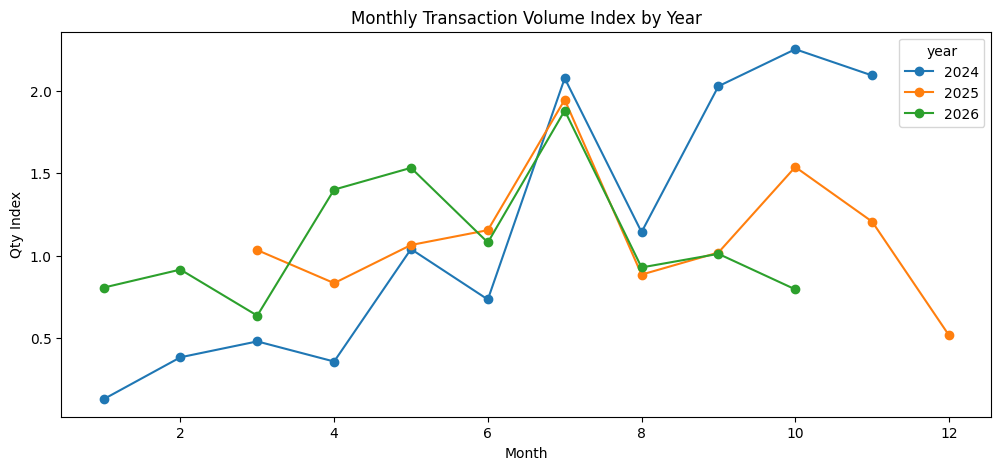

In [44]:
qty_pivot.plot(
    figsize=(12, 5),
    marker="o",
    title="Monthly Transaction Volume Index by Year"
)

plt.xlabel("Month")
plt.ylabel("Qty Index")
plt.show()

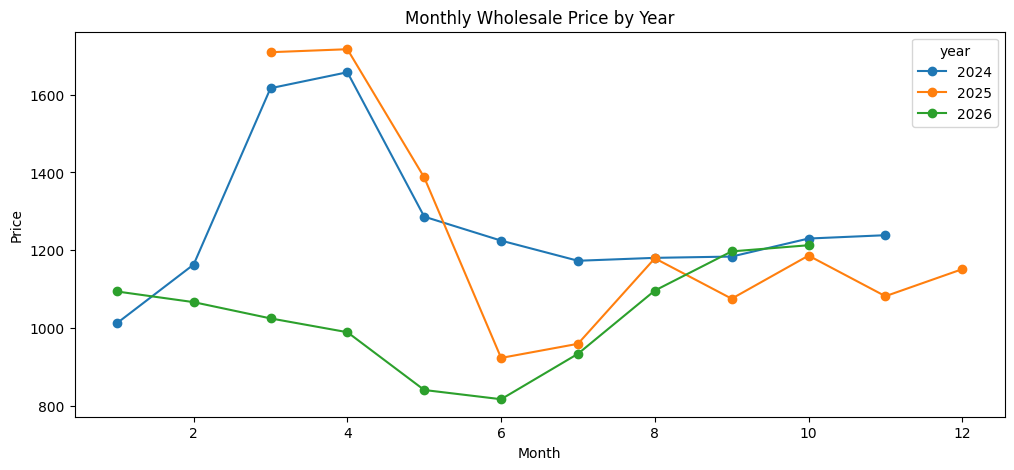

In [45]:
wholesale_price_pivot.plot(
    figsize=(12, 5),
    marker="o",
    title="Monthly Wholesale Price by Year"
)

plt.xlabel("Month")
plt.ylabel("Price")
plt.show()

In [46]:
monthly_analysis = (
    weekly.groupby(["year", "month"])
    .agg(
        weeks_total=("date", "count"),

        qty_weeks=(
            "avg_daily_wholesale_qty",
            "count"
        ),

        wholesale_price_weeks=(
            "wholesale_price",
            "count"
        ),

        retail_price_weeks=(
            "retail_price",
            "count"
        ),

        qty_index=(
            "qty_index",
            "median"
        ),

        wholesale_price=(
            "wholesale_price",
            "median"
        ),

        retail_price=(
            "retail_price",
            "median"
        )
    )
    .reset_index()
)

monthly_analysis

,year,month,weeks_total,qty_weeks,wholesale_price_weeks,retail_price_weeks,qty_index,wholesale_price,retail_price
0,2023,10,2,2,2,2,0.594444,1408.500000,2285.0
1,2023,11,4,4,4,4,0.980000,1222.250000,1980.0
2,2023,12,5,5,4,5,2.179000,1151.500000,2320.0
3,2024,1,4,4,4,4,0.125480,1012.500000,2320.0
4,2024,2,4,4,4,4,0.380696,1163.500000,2290.0
5,2024,3,5,5,5,5,0.477416,1616.500000,2320.0
6,2024,4,4,4,4,4,0.354865,1657.498953,2585.0
7,2024,5,4,4,4,4,1.039370,1286.487442,2240.0
8,2024,6,5,5,5,5,0.732455,1224.932392,2210.0
9,2024,7,4,4,4,4,2.078915,1173.164091,1922.5


In [47]:
monthly_analysis["qty_coverage"] = (
    monthly_analysis["qty_weeks"]
    / monthly_analysis["weeks_total"]
)

monthly_analysis["wholesale_price_coverage"] = (
    monthly_analysis["wholesale_price_weeks"]
    / monthly_analysis["weeks_total"]
)

monthly_analysis["retail_price_coverage"] = (
    monthly_analysis["retail_price_weeks"]
    / monthly_analysis["weeks_total"]
)

In [48]:
monthly_analysis["is_reliable_month"] = (
    (monthly_analysis["qty_coverage"] >= 0.75) &
    (monthly_analysis["wholesale_price_coverage"] >= 0.75) &
    (monthly_analysis["retail_price_coverage"] >= 0.75)
)

In [49]:
monthly_analysis["wholesale_price_index"] = (
    monthly_analysis["wholesale_price"]
    /
    monthly_analysis.groupby("year")[
        "wholesale_price"
    ].transform("median")
)

monthly_analysis["retail_price_index"] = (
    monthly_analysis["retail_price"]
    /
    monthly_analysis.groupby("year")[
        "retail_price"
    ].transform("median")
)

In [50]:
daily_month_coverage = (
    df.assign(
        year=df["date"].dt.year,
        month=df["date"].dt.month
    )
    .groupby(["year", "month"])
    .agg(
        calendar_days=("date", "count")
    )
    .reset_index()
)

daily_month_coverage["days_in_month"] = pd.to_datetime(
    dict(
        year=daily_month_coverage["year"],
        month=daily_month_coverage["month"],
        day=1
    )
).dt.days_in_month

daily_month_coverage["calendar_coverage"] = (
    daily_month_coverage["calendar_days"]
    / daily_month_coverage["days_in_month"]
)

In [51]:
monthly_analysis = monthly_analysis.merge(
    daily_month_coverage,
    on=["year", "month"],
    how="left"
)

In [52]:
monthly_analysis["qty_coverage"] = (
    monthly_analysis["qty_weeks"]
    / monthly_analysis["weeks_total"]
)

monthly_analysis["wholesale_price_coverage"] = (
    monthly_analysis["wholesale_price_weeks"]
    / monthly_analysis["weeks_total"]
)

monthly_analysis["retail_price_coverage"] = (
    monthly_analysis["retail_price_weeks"]
    / monthly_analysis["weeks_total"]
)

In [53]:
monthly_analysis["is_reliable_month"] = (
    (monthly_analysis["calendar_coverage"] >= 0.95) &
    (monthly_analysis["qty_coverage"] >= 0.75) &
    (monthly_analysis["wholesale_price_coverage"] >= 0.75) &
    (monthly_analysis["retail_price_coverage"] >= 0.75)
)

In [54]:
monthly_analysis[
    [
        "year",
        "month",
        "calendar_coverage",
        "qty_coverage",
        "wholesale_price_coverage",
        "retail_price_coverage",
        "is_reliable_month"
    ]
]

,year,month,calendar_coverage,qty_coverage,wholesale_price_coverage,retail_price_coverage,is_reliable_month
0,2023,10,0.516129,1.0,1.0,1.0,False
1,2023,11,1.000000,1.0,1.0,1.0,True
2,2023,12,1.000000,1.0,0.8,1.0,True
3,2024,1,1.000000,1.0,1.0,1.0,True
4,2024,2,1.000000,1.0,1.0,1.0,True
5,2024,3,1.000000,1.0,1.0,1.0,True
6,2024,4,1.000000,1.0,1.0,1.0,True
7,2024,5,1.000000,1.0,1.0,1.0,True
8,2024,6,1.000000,1.0,1.0,1.0,True
9,2024,7,1.000000,1.0,1.0,1.0,True


In [55]:
analysis_monthly = monthly_analysis[
    monthly_analysis["is_reliable_month"]
].copy()

In [56]:
analysis_monthly["wholesale_price_index"] = (
    analysis_monthly["wholesale_price"]
    /
    analysis_monthly.groupby("year")[
        "wholesale_price"
    ].transform("median")
)

analysis_monthly["retail_price_index"] = (
    analysis_monthly["retail_price"]
    /
    analysis_monthly.groupby("year")[
        "retail_price"
    ].transform("median")
)

In [57]:
analysis_monthly = monthly_analysis[
    monthly_analysis["is_reliable_month"]
].copy()

analysis_monthly_core = analysis_monthly[
    analysis_monthly["year"] >= 2024
].copy()

print(len(analysis_monthly))
print(len(analysis_monthly_core))

32
30
